In [ ]:
# Importing the data from Kaggle

import kagglehub
dataset_path = kagglehub.dataset_download('kamilpytlak/personal-key-indicators-of-heart-disease', output_dir="Data")

print('Data source import complete.')


100%|██████████| 21.4M/21.4M [00:06<00:00, 3.40MB/s]

Extracting files...


Data source import complete.


# Personal Key Indicators of Heart Disease

Heart disease (heart disease) is a group of diseases related to cardiovascular diseases, manifested by a violation of the normal functioning of the heart. May be caused by damage to the epicardium, pericardium, myocardium, endocardium, valvular apparatus of the heart, heart vessels.

Heart disease can last a long time in a latent form, clinically not manifesting itself. Along with various tumors, these diseases are today the main cause of premature death in developed countries.

The uninterrupted operation of the circulatory system, which consists of the heart as a muscle pump and a network of blood vessels, is a necessary condition for the normal functioning of the body.

According to the National Heart, Lung and Blood Institute in Framingham (USA), the most important factors in the development of cardiovascular disease in humans are obesity, sedentary lifestyle and smoking.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import missingno as msno
from scipy import stats

In [37]:
dataset = pd.read_csv('Data/2020/heart_2020_cleaned.csv')

Let's get some basic info about the dataset

In [80]:
dataset.describe().style.background_gradient(cmap = "summer")

,BMI,PhysicalHealth,MentalHealth,SleepTime
count,319795.000000,319795.000000,319795.000000,319795.000000
mean,28.325399,3.371710,3.898366,7.097075
std,6.356100,7.950850,7.955235,1.436007
min,12.020000,0.000000,0.000000,1.000000
25%,24.030000,0.000000,0.000000,6.000000
50%,27.340000,0.000000,0.000000,7.000000
75%,31.420000,2.000000,3.000000,8.000000
max,94.850000,30.000000,30.000000,24.000000


In [63]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 319795 entries, 0 to 319794
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   HeartDisease      319795 non-null  str    
 1   BMI               319795 non-null  float64
 2   Smoking           319795 non-null  str    
 3   AlcoholDrinking   319795 non-null  str    
 4   Stroke            319795 non-null  str    
 5   PhysicalHealth    319795 non-null  float64
 6   MentalHealth      319795 non-null  float64
 7   DiffWalking       319795 non-null  str    
 8   Sex               319795 non-null  str    
 9   AgeCategory       319795 non-null  str    
 10  Race              319795 non-null  str    
 11  Diabetic          319795 non-null  str    
 12  PhysicalActivity  319795 non-null  str    
 13  GenHealth         319795 non-null  str    
 14  SleepTime         319795 non-null  float64
 15  Asthma            319795 non-null  str    
 16  KidneyDisease     319795 non-nu

The data sample is very informative and is represented by 319 thousand patients on 18 criteria.

What features characterize our data sample?

* HeartDisease - target trait.
* BMI - a value that allows you to assess the degree of correspondence between a person's mass and his height, and thereby indirectly judge whether the mass is insufficient, normal or excessive. It is important in determining the indications for the need for treatment.
* Smoking is a major risk factor for cardiovascular disease. When smoke from a cigarette is inhaled, the reaction of the cardiovascular system immediately follows: within one minute, the heart rate begins to rise, increasing by 30% within ten minutes of smoking. The bad habit also increases blood pressure, fibrinogen and platelet levels, making blood clots more likely.
* AlcoholDrinking - alcohol causes not only temporary disturbances in the functioning of the heart, but also permanent ones. Heart pain after alcohol is not the only health problem associated with alcohol consumption.
* Stroke - Ischemic stroke occurs 4 times more often than hemorrhagic. One of the leading causes of this suffering is heart disease, which impairs its functioning, as a result of which the blood flow in the arteries is disturbed and the blood supply to the brain is reduced. Another cause of stroke in heart disease is thromboembolism, when clots form in the cavities of the heart (most often with heart failure) - blood clots.
* PhysicalHealth - how many days in a month did you feel poor physical health.
* MentalHealth - how many days in a month did you feel poor mental health.
* DiffWalking - difficulty climbing stairs.
* Sex - gender of a person.
* AgeCategory - age category of the subjects.
*Race-obviously:)
* Diabetic - obviously :)
* PhysicalActivity - adults who reported doing physical activity or exercise during the past 30 days other than their regular job
* GenHealth - well-being.
* SleepTime - number of hours of sleep.
* Asthma- obviously :)
* KidneyDisease - obviously :)
* Skin Cancer - obviously :)

Lets Check for any missing values/gaps in the dataset

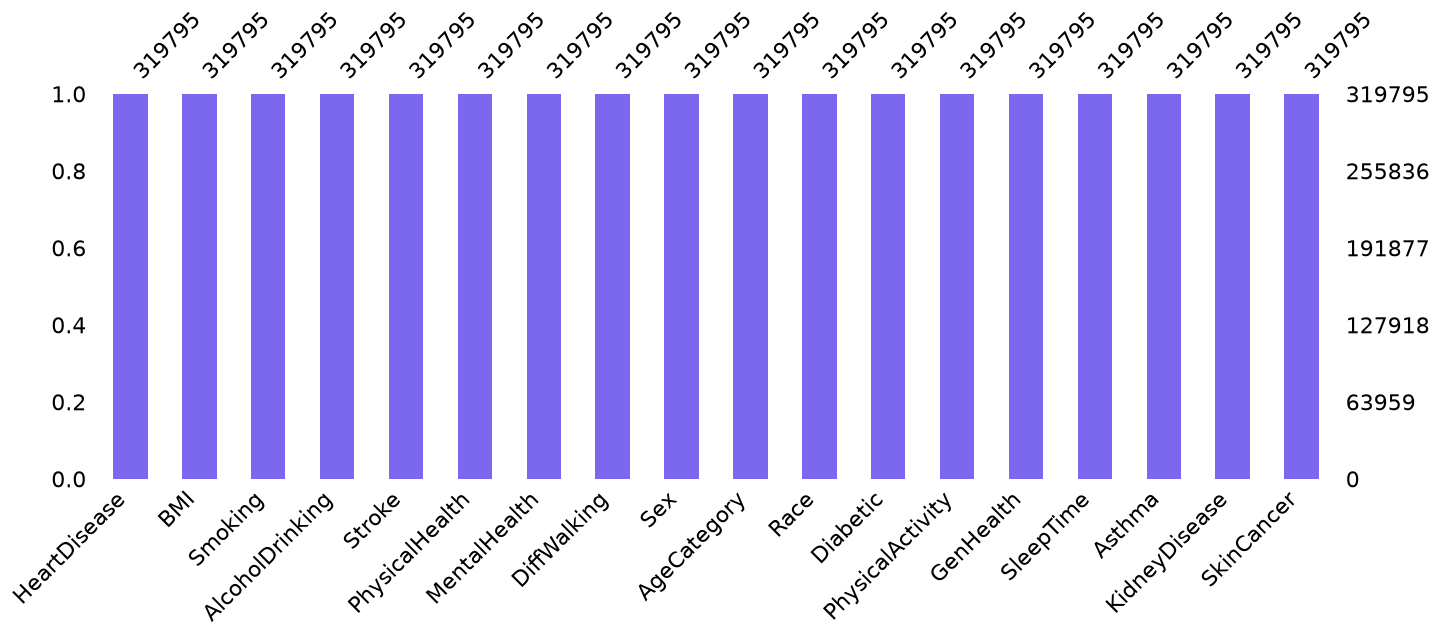

In [81]:
msno.bar(dataset, figsize = (16,5),color = "#7B68EE")
plt.show()

There are no missing values!

Let's look at the distribution of the target variable

<Axes: xlabel='HeartDisease', ylabel='count'>

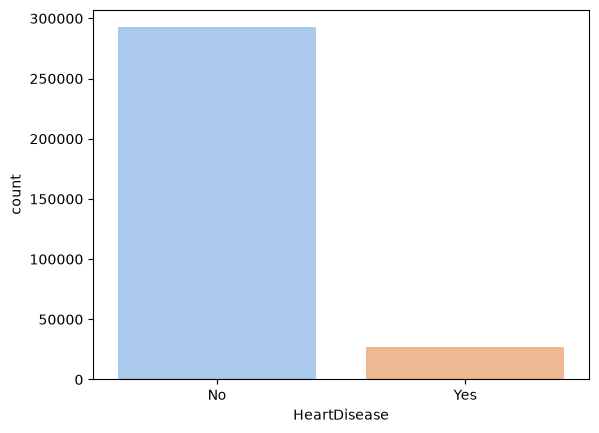

In [ ]:
sns.countplot(x='HeartDisease',data = dataset,palette='pastel')


We are dealing with an unbalanced sample, where the majority of people are healthy.

Let's look at unique values in categorical objects

In [83]:
for column_name in dataset.columns:
    unique_values = len(dataset[column_name].unique())
    print("Feature '{column_name}' has '{unique_values}' unique values".format(column_name = column_name,
                                                                                         unique_values=unique_values))

Feature 'HeartDisease' has '2' unique values
Feature 'BMI' has '3604' unique values
Feature 'Smoking' has '2' unique values
Feature 'AlcoholDrinking' has '2' unique values
Feature 'Stroke' has '2' unique values
Feature 'PhysicalHealth' has '31' unique values
Feature 'MentalHealth' has '31' unique values
Feature 'DiffWalking' has '2' unique values
Feature 'Sex' has '2' unique values
Feature 'AgeCategory' has '13' unique values
Feature 'Race' has '6' unique values
Feature 'Diabetic' has '4' unique values
Feature 'PhysicalActivity' has '2' unique values
Feature 'GenHealth' has '5' unique values
Feature 'SleepTime' has '24' unique values
Feature 'Asthma' has '2' unique values
Feature 'KidneyDisease' has '2' unique values
Feature 'SkinCancer' has '2' unique values


Numeric variables are BMI, PhysicalHealth, MentalHealth, SleepTime. The rest are categorical.

In [84]:
numeric_features=['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']
categorical_features=['HeartDisease', 'Smoking', 'AlcoholDrinking', 'Stroke', 'DiffWalking', 'Sex', 'AgeCategory',
       'Race', 'Diabetic', 'PhysicalActivity', 'GenHealth','Asthma', 'KidneyDisease', 'SkinCancer']

Let's analyze numerical variables.

Text(0.5, 0.98, 'Visualizing continuous columns (train dataset)')

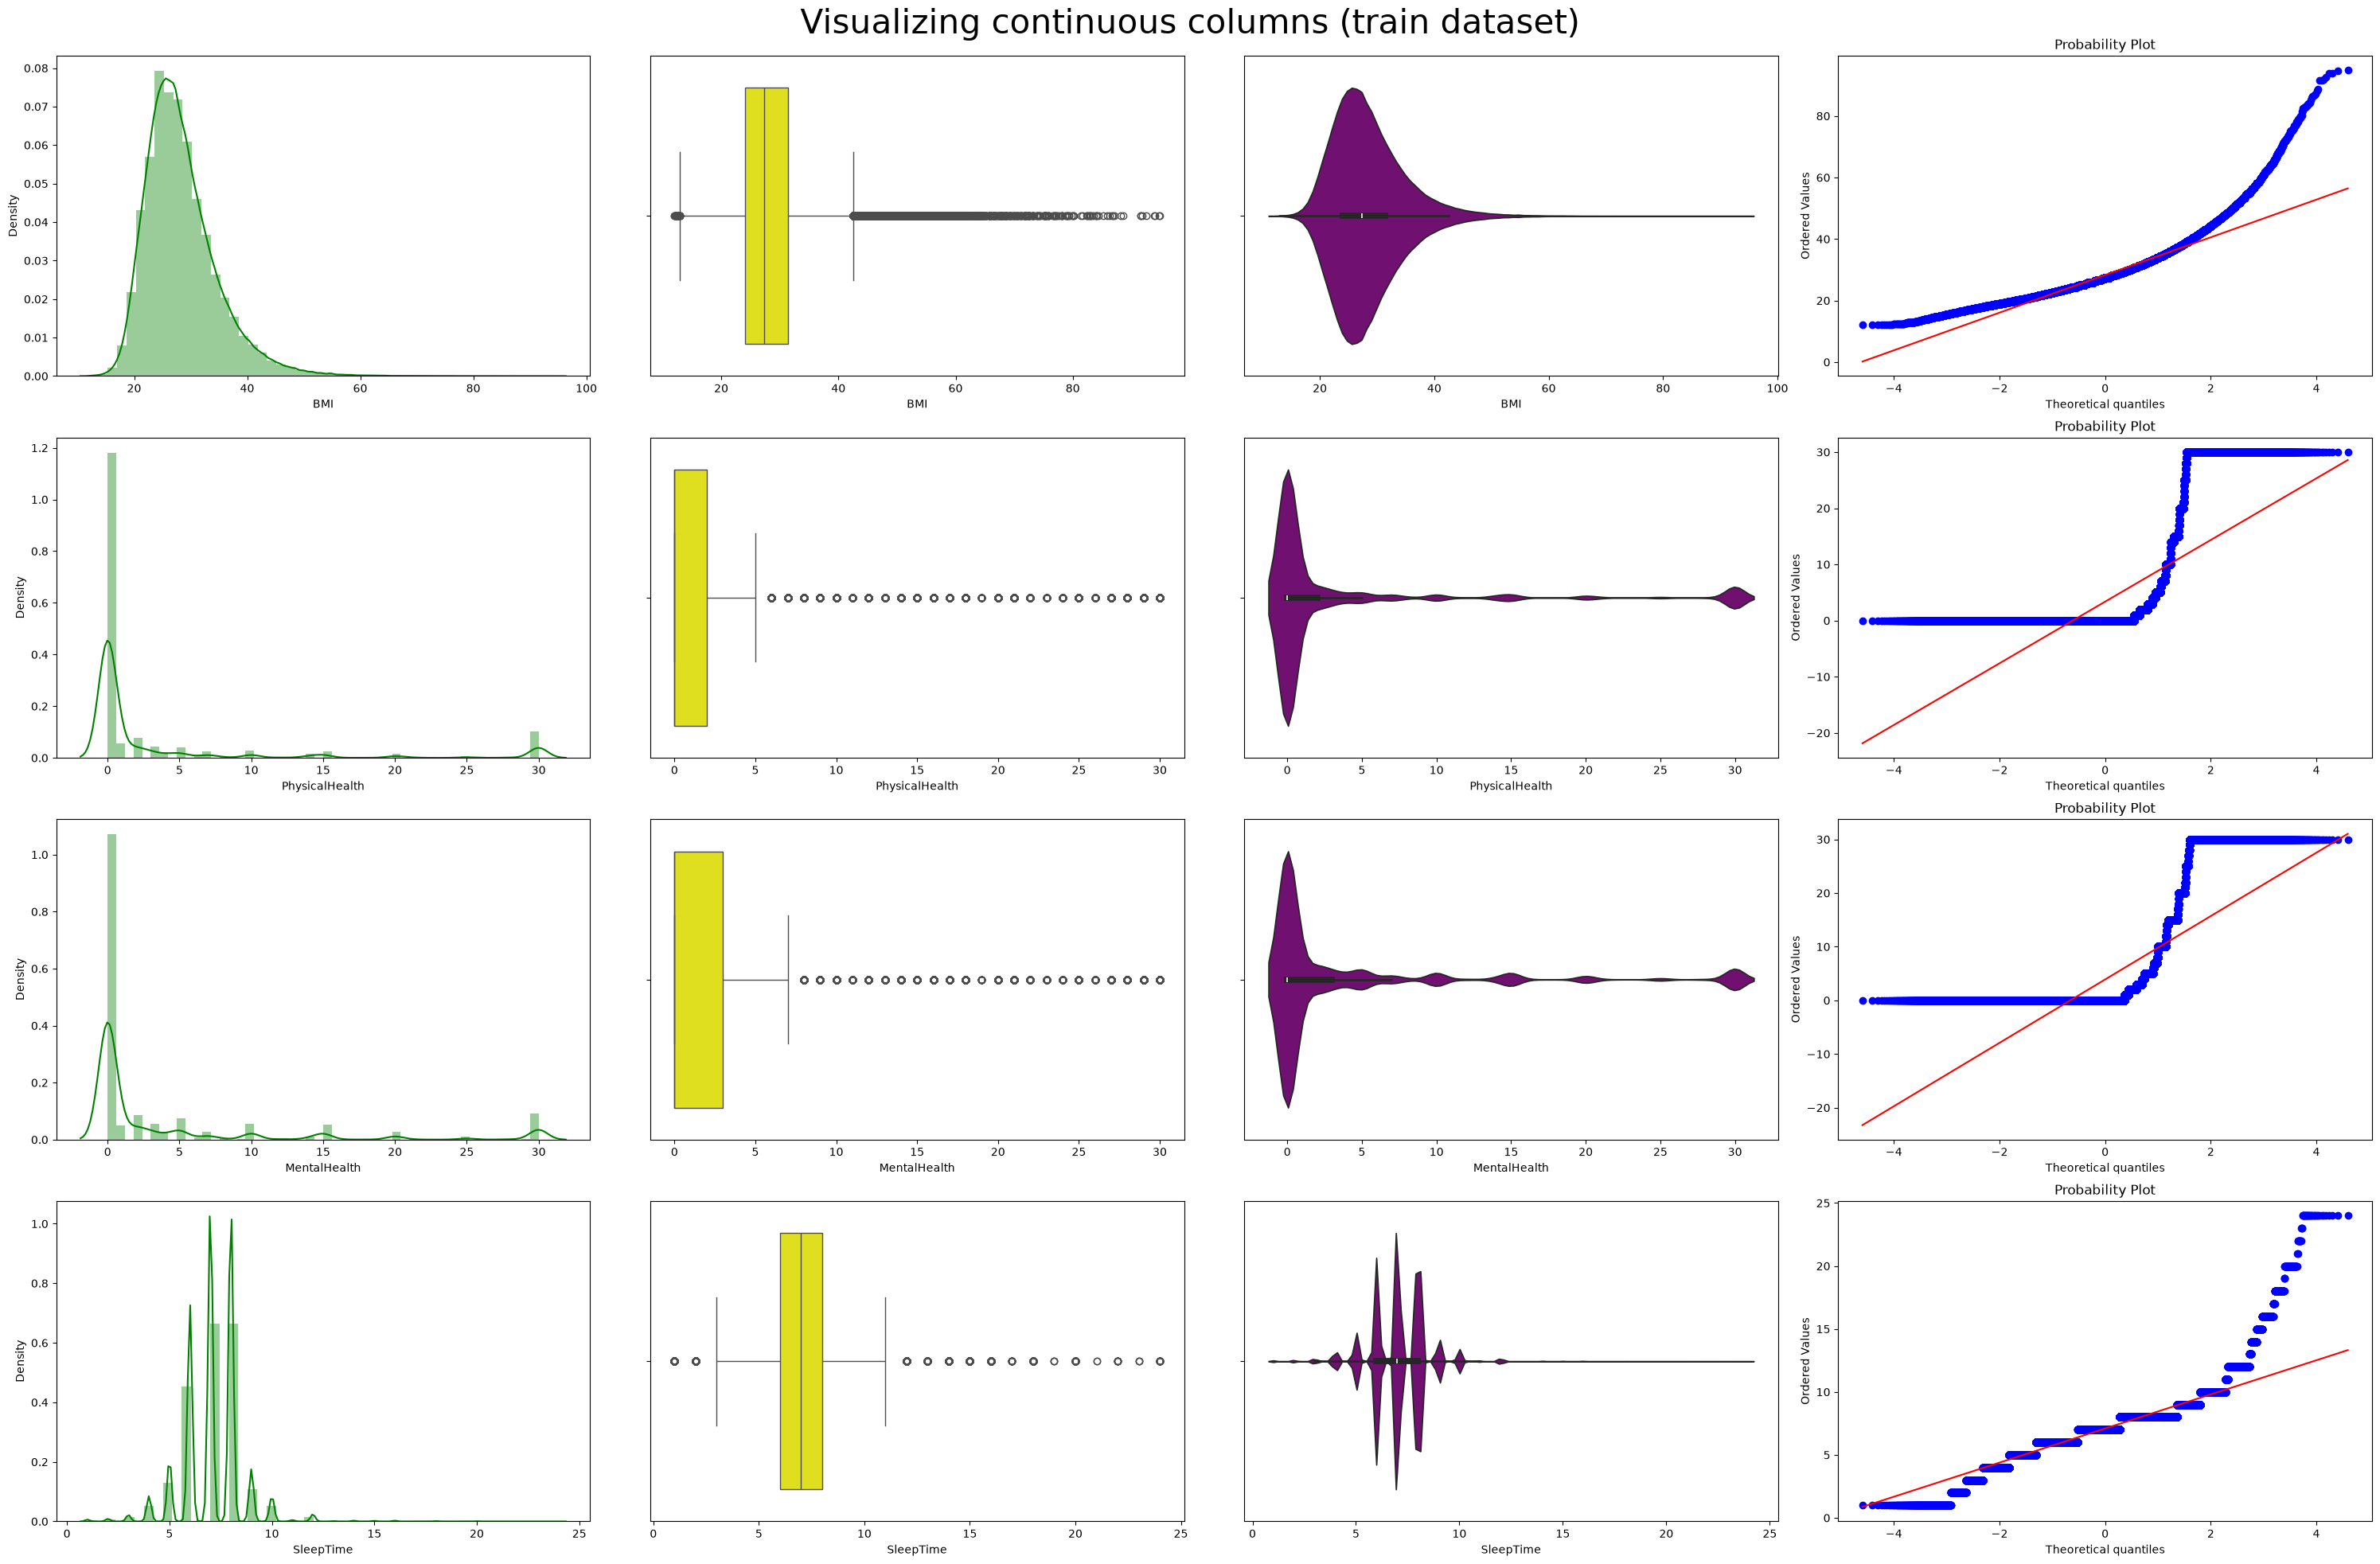

In [85]:
import warnings

warnings.filterwarnings('ignore')

fig, ax = plt.subplots(
    len(numeric_features), 4,
    figsize=(30, 20)
)

for index, feature in enumerate(numeric_features):
    sns.distplot(
        dataset[feature],
        ax=ax[index, 0],
        color='green'
    )
    sns.boxplot(
        x=dataset[feature],
        ax=ax[index, 1],
        color='yellow'
    )
    sns.violinplot(
        x=dataset[feature],
        ax=ax[index, 2],
        color='purple'
    )
    stats.probplot(
        dataset[feature],
        plot=ax[index, 3]
    )

fig.tight_layout()
fig.subplots_adjust(top=0.95)
plt.suptitle(
    "Visualizing continuous columns (train dataset)",
    fontsize=30
)

The analysis showed that only the BMI variable is close to the normal distribution, the rest are close to bimodal.

Let's look at the distribution of the number of people with heart disease from various factors

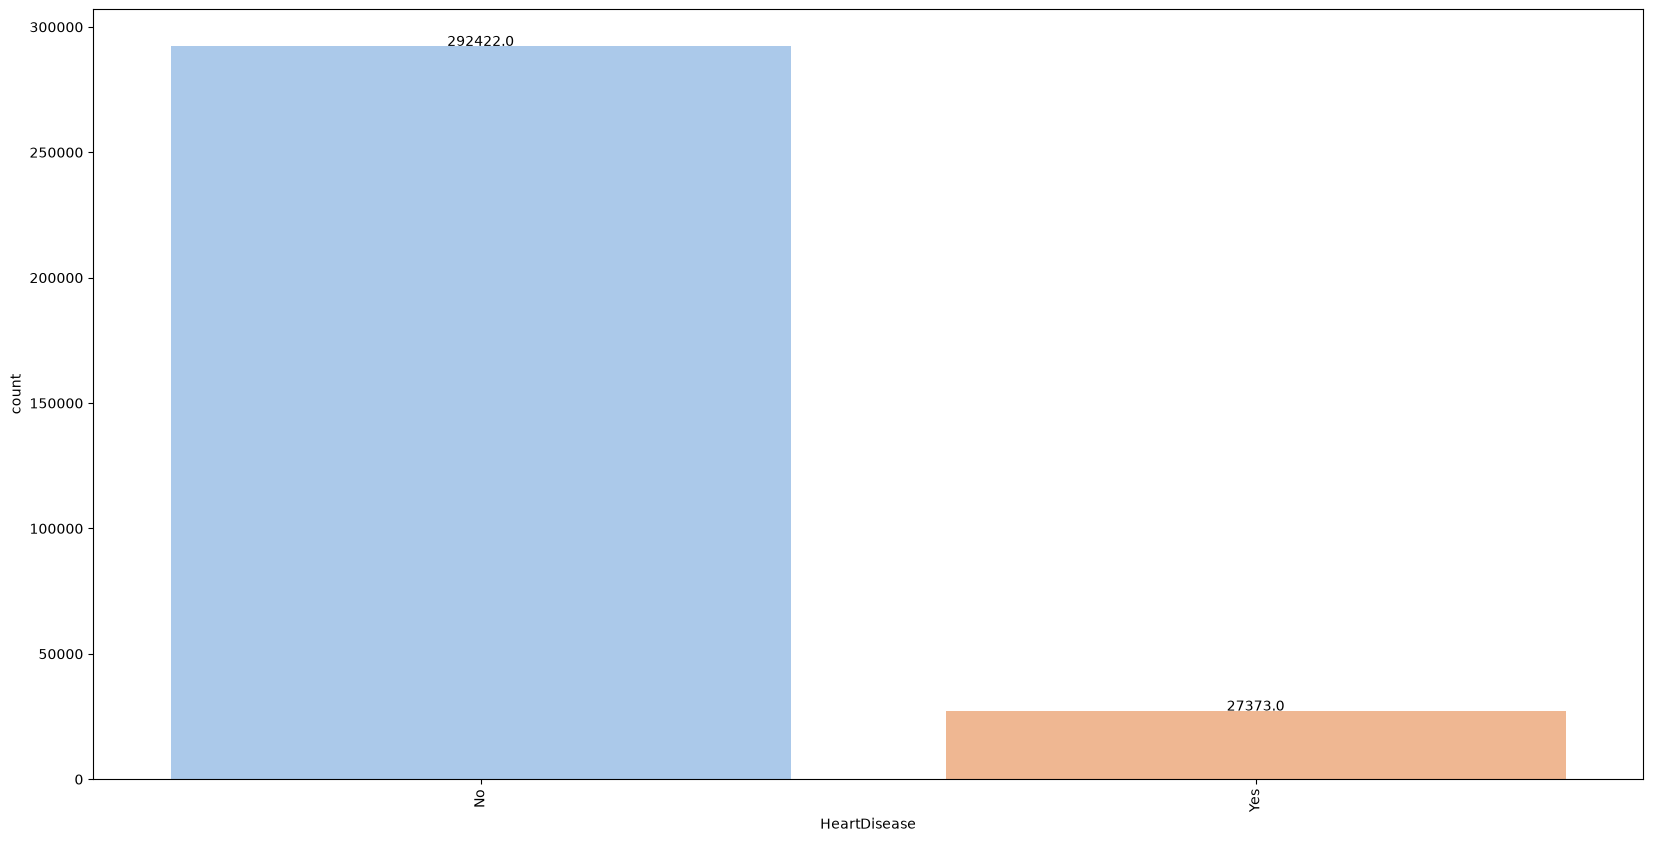

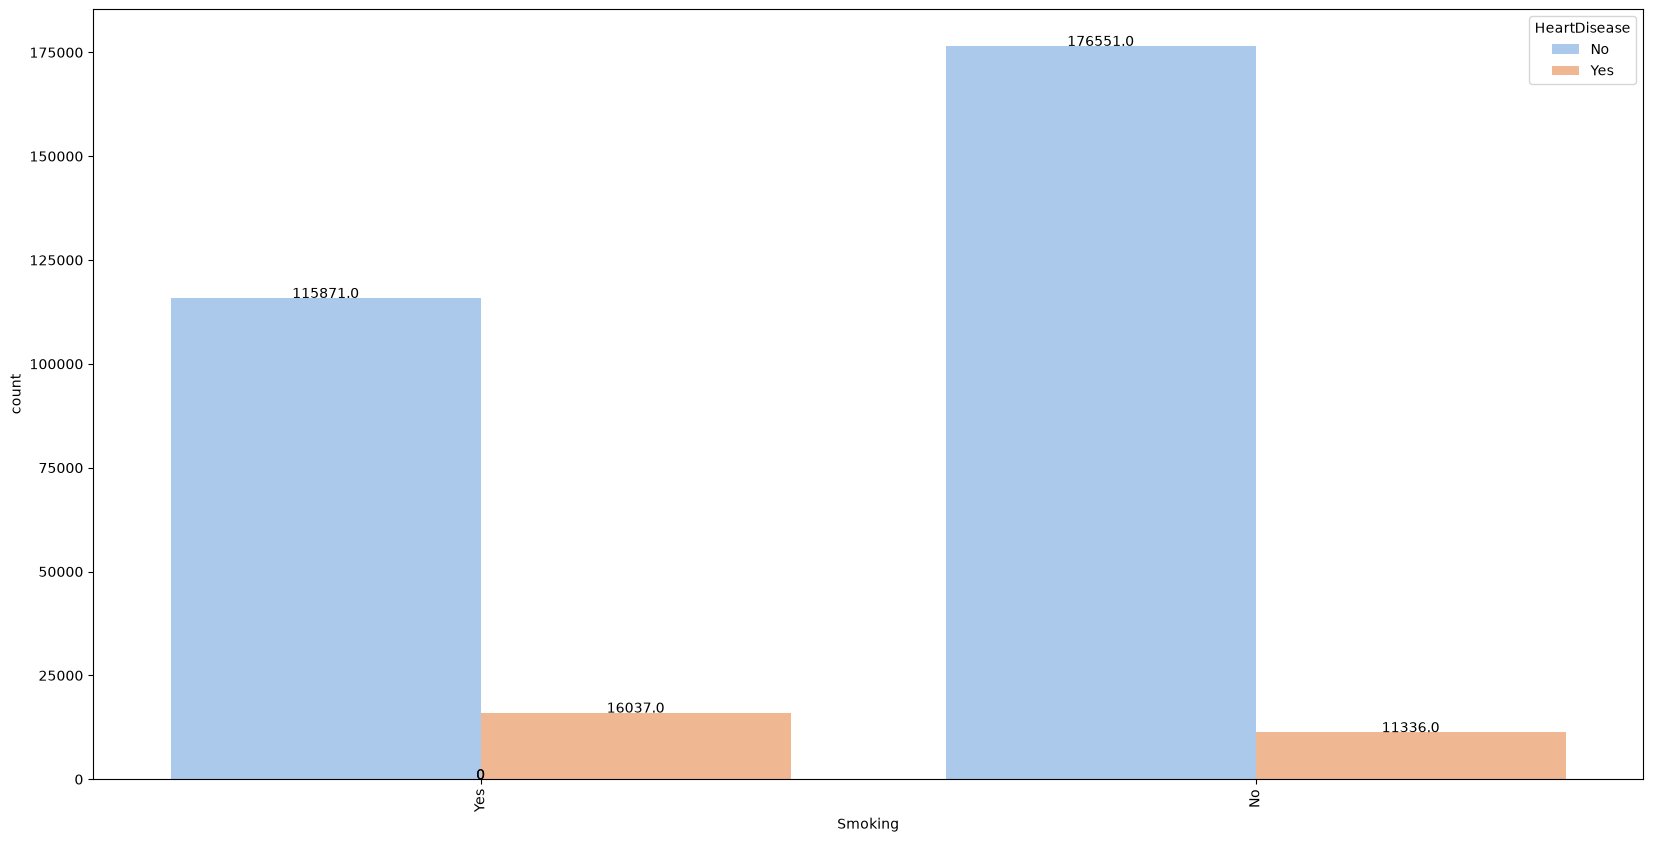

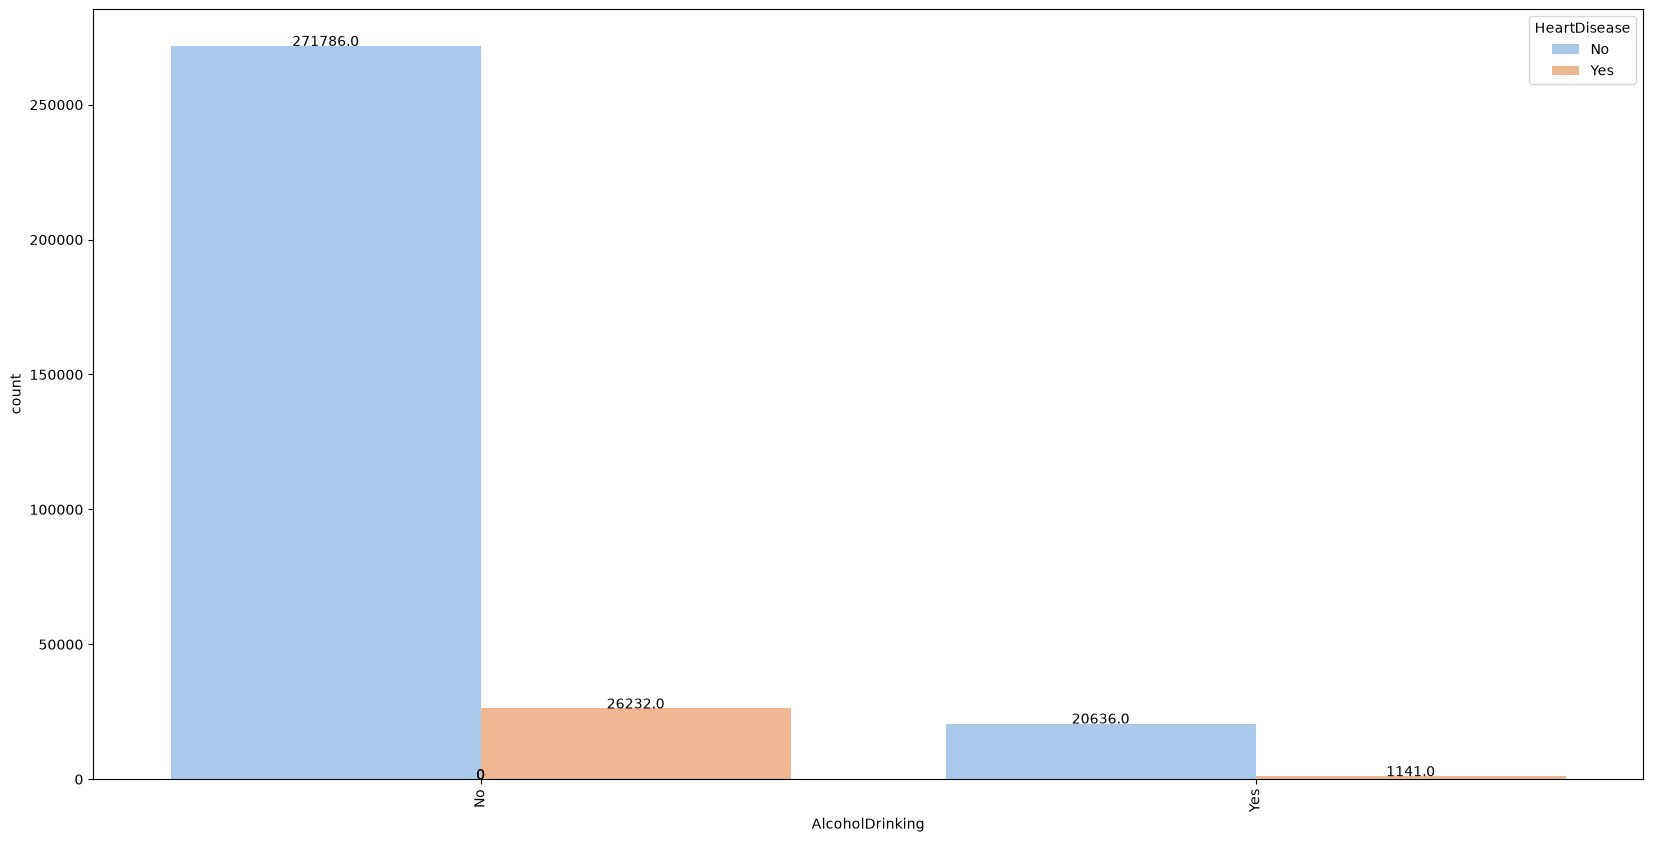

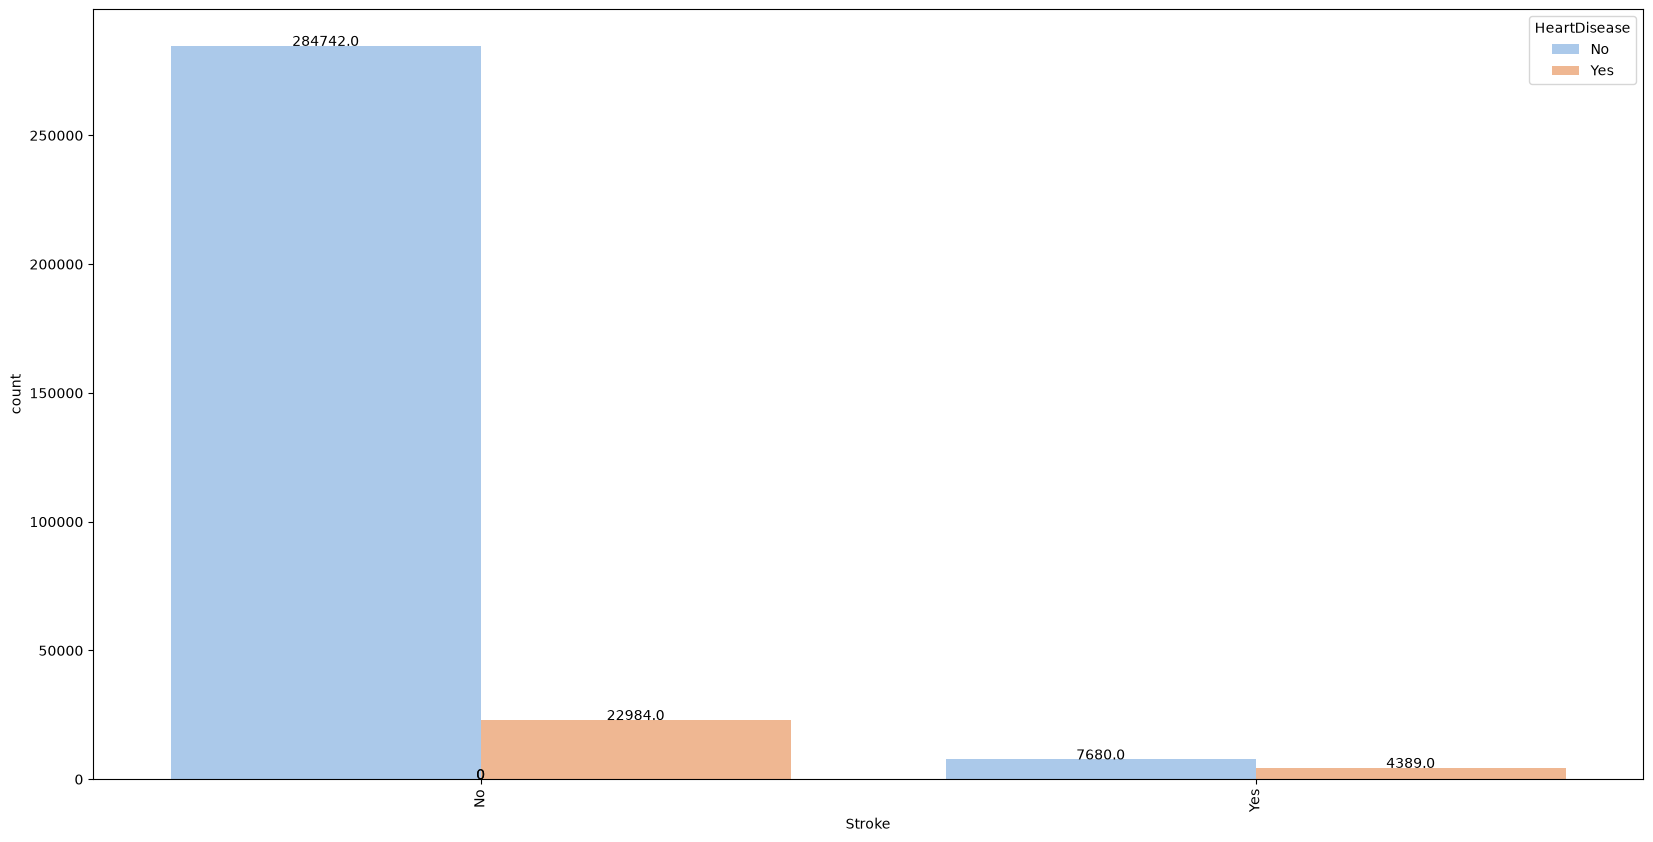

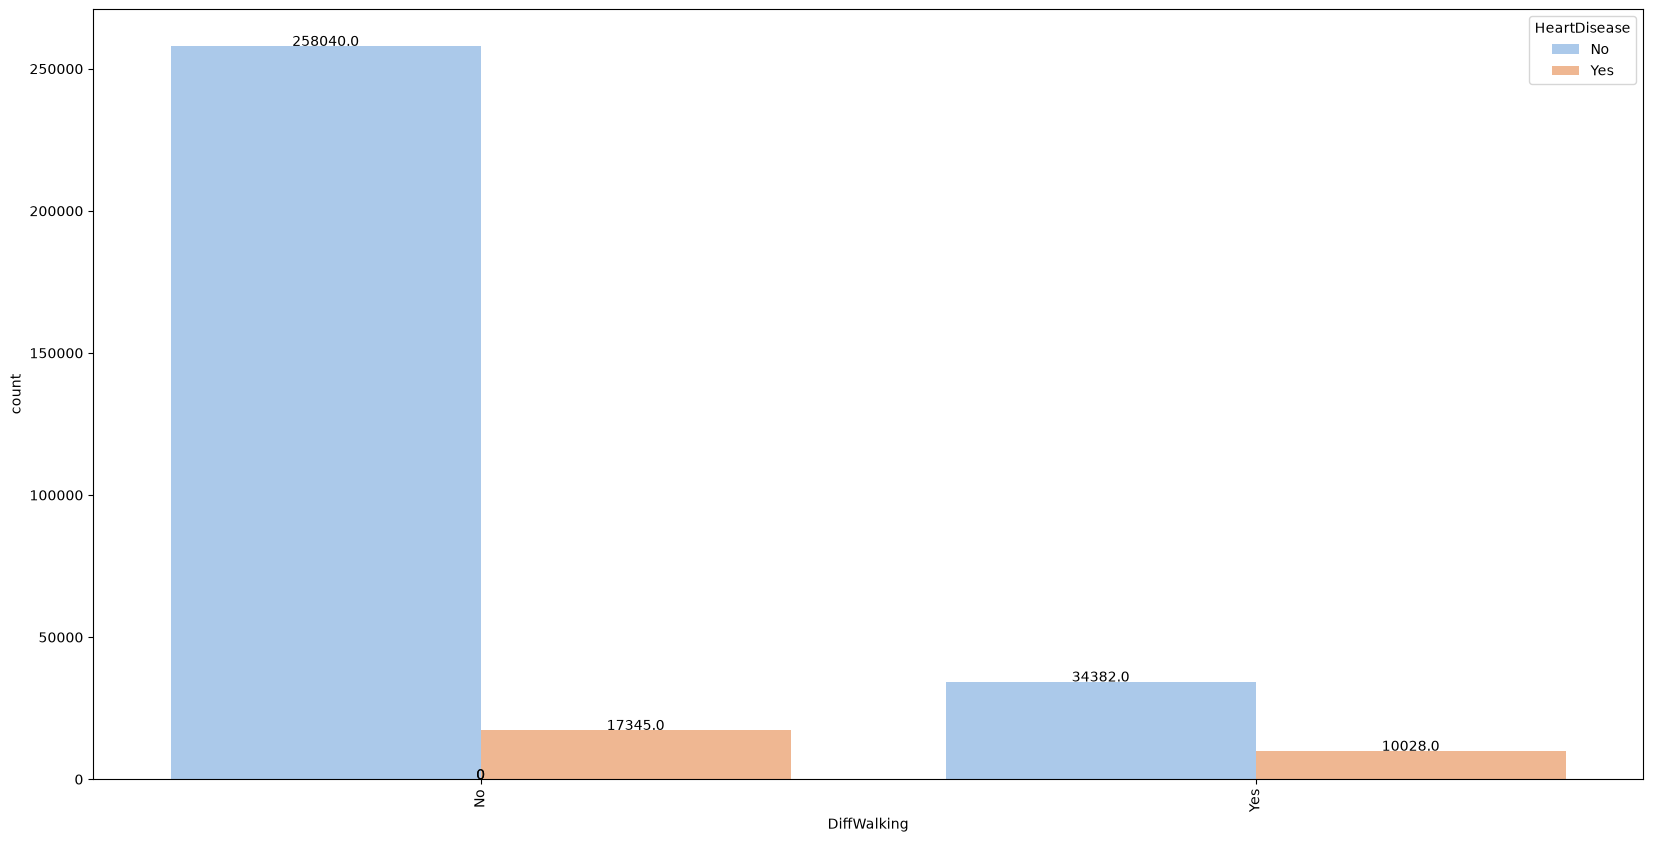

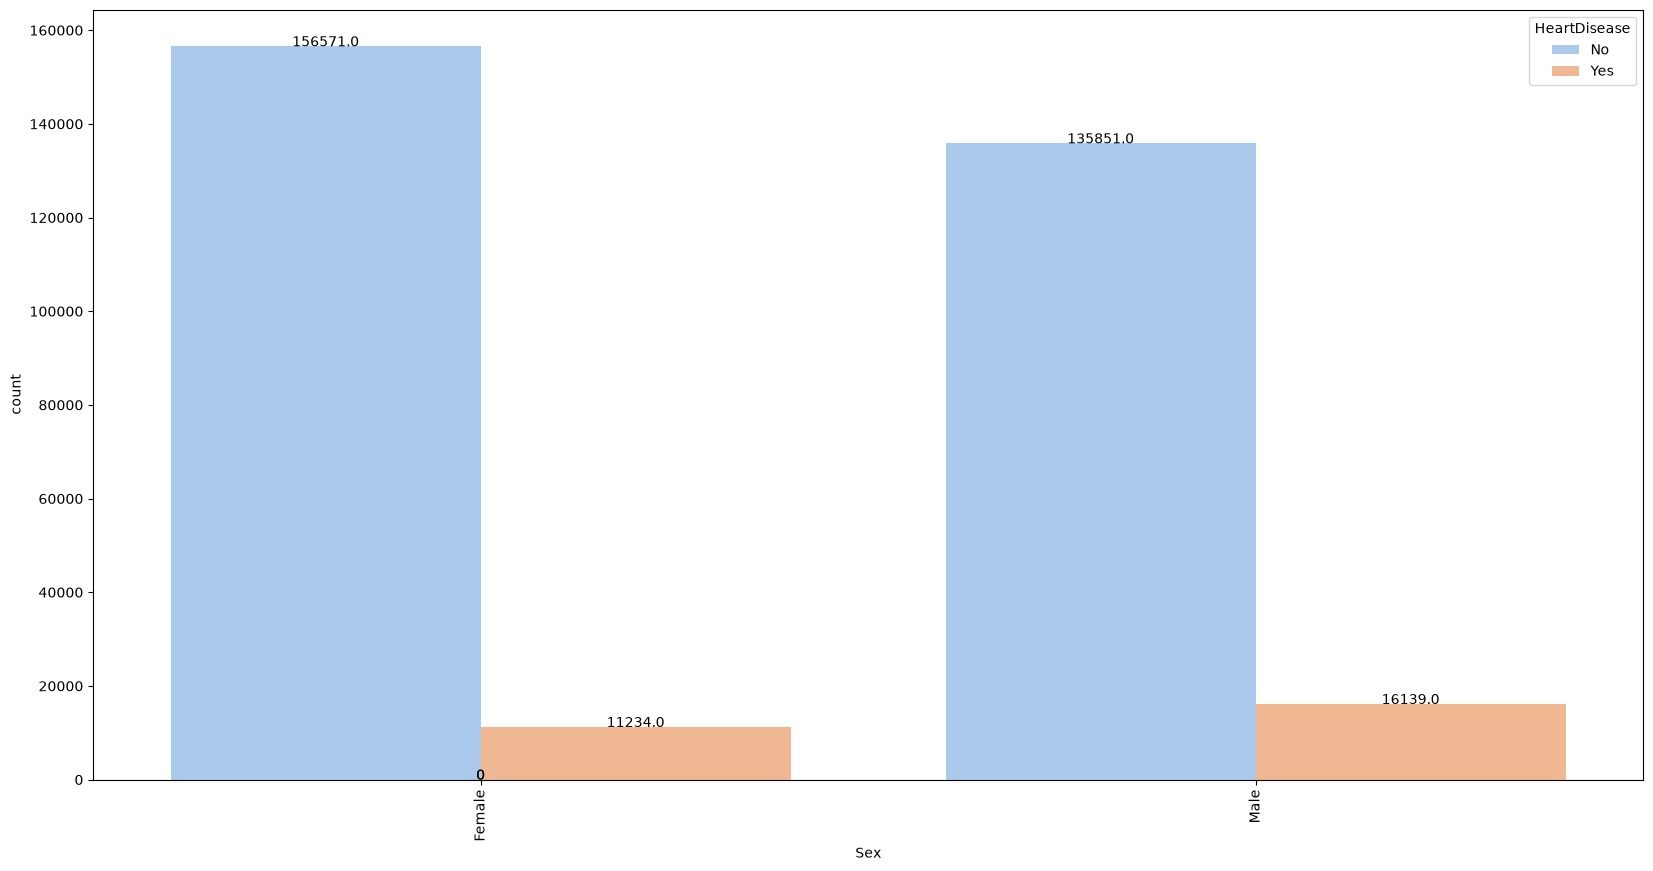

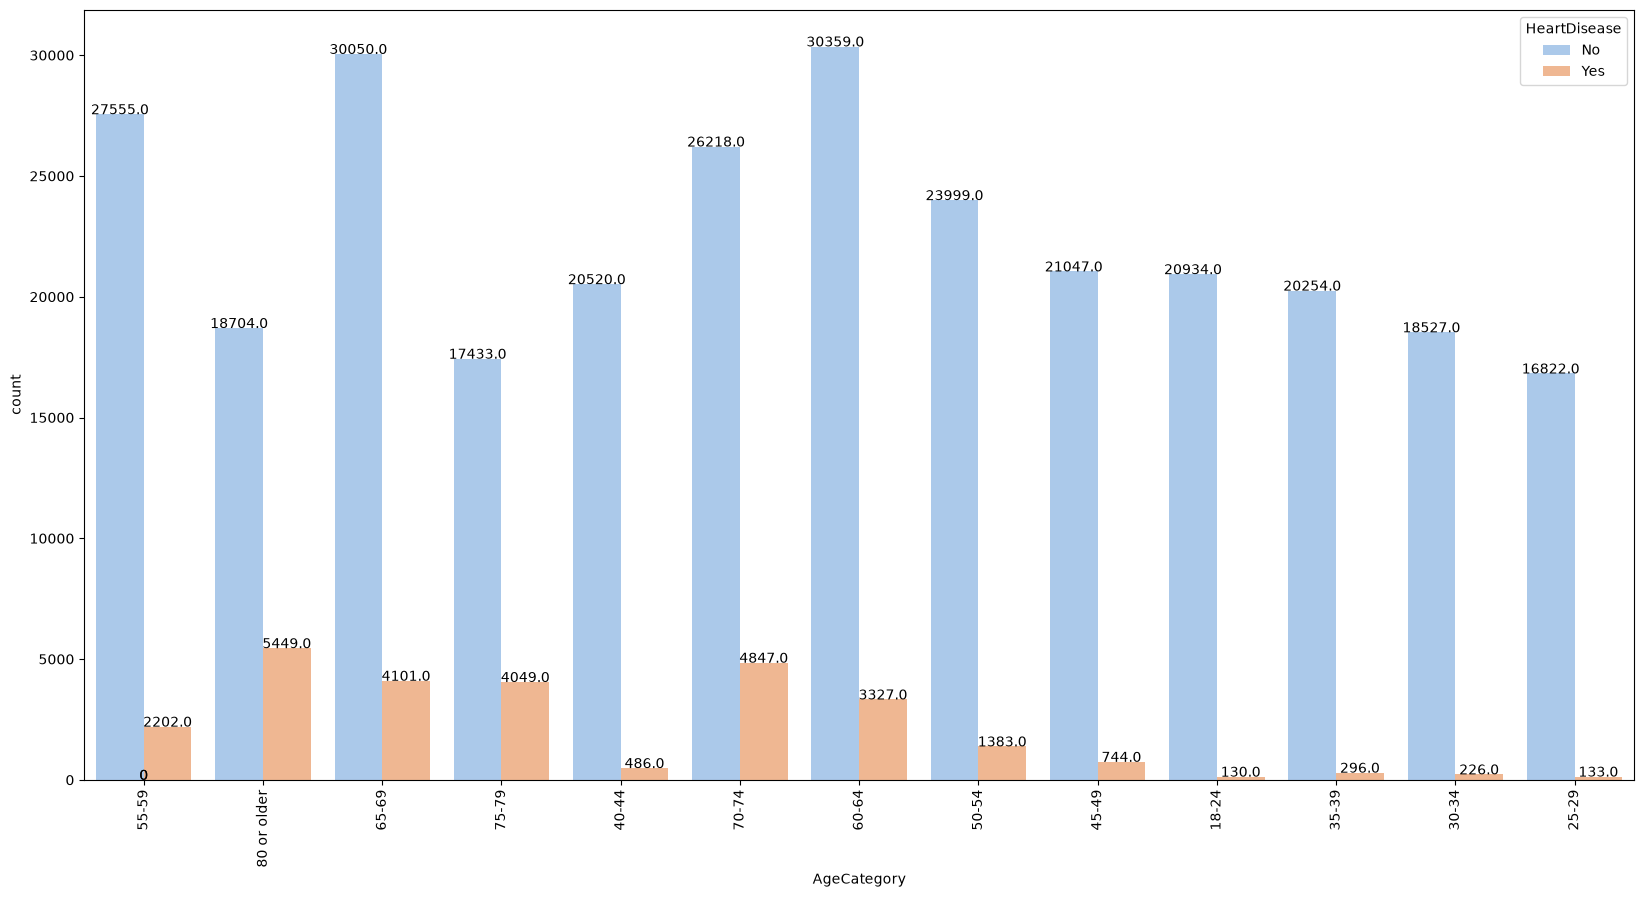

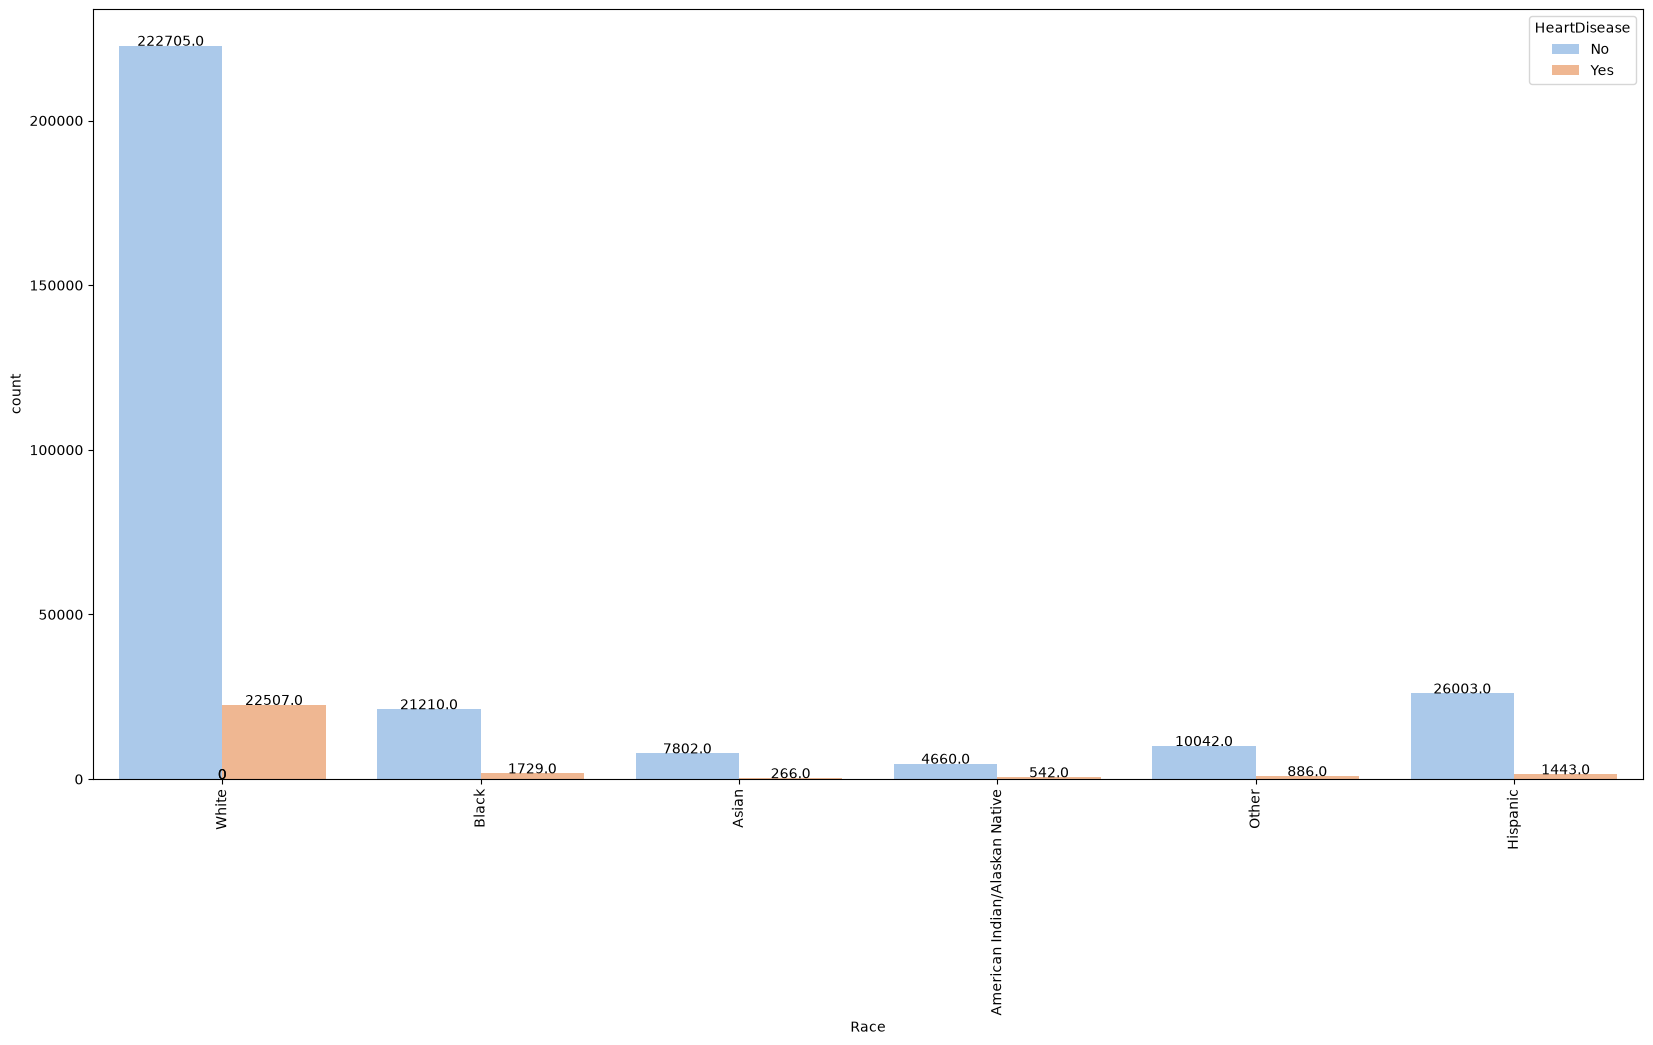

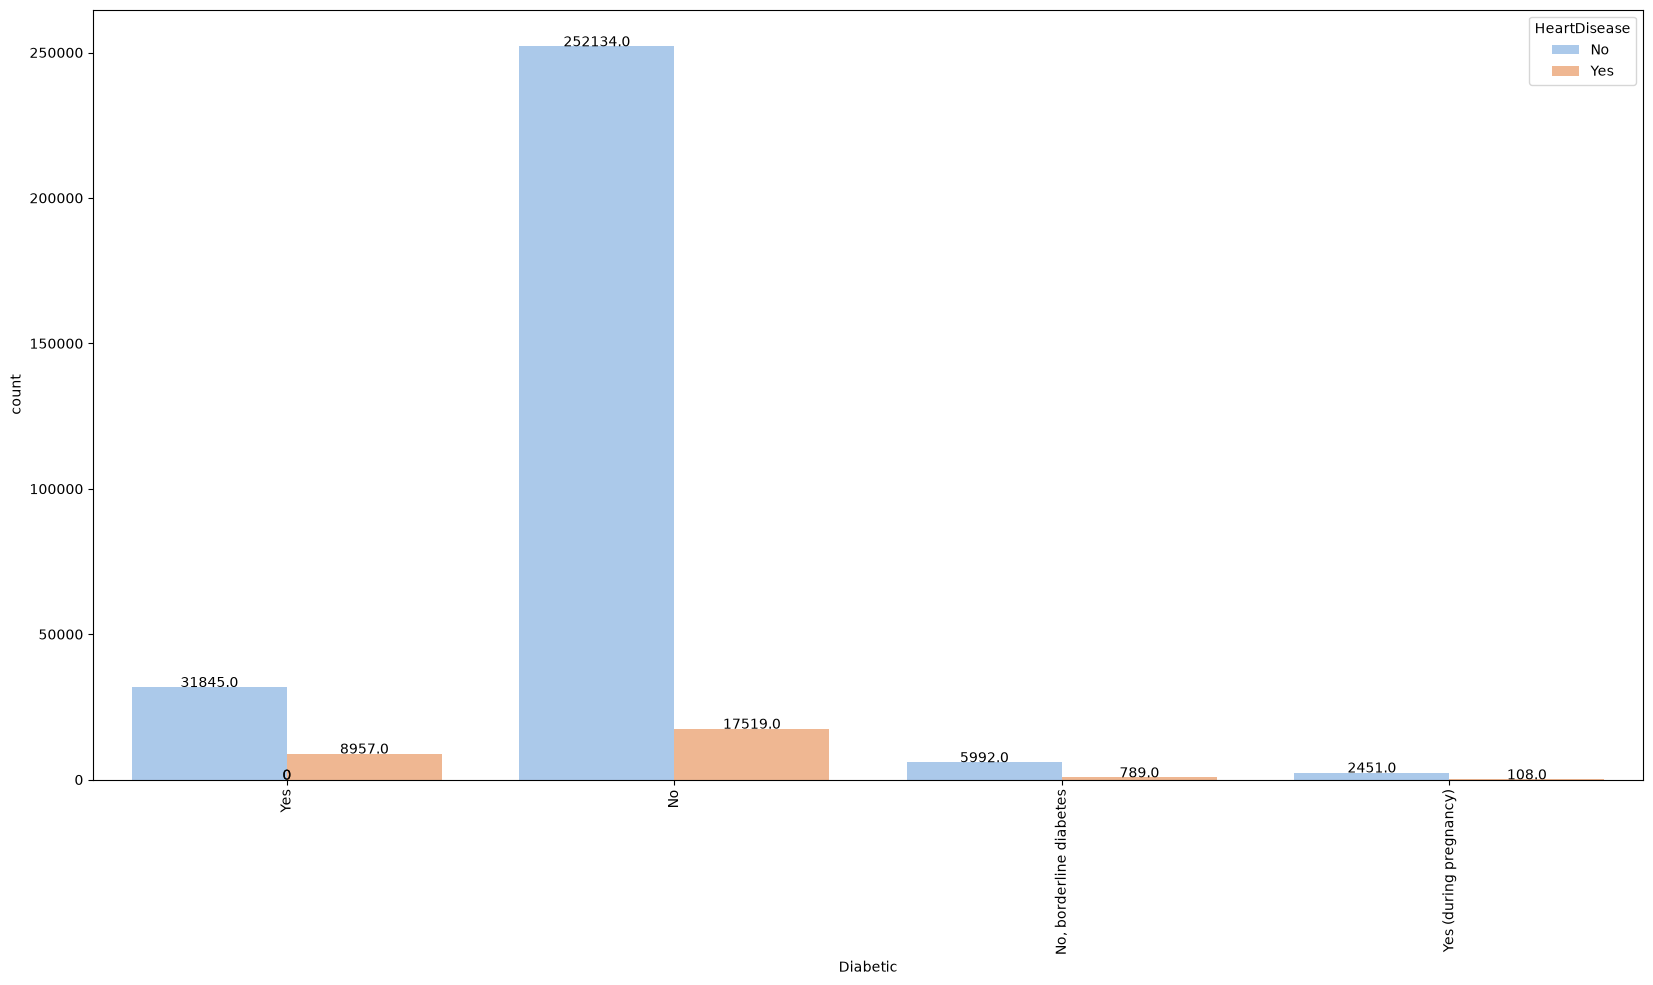

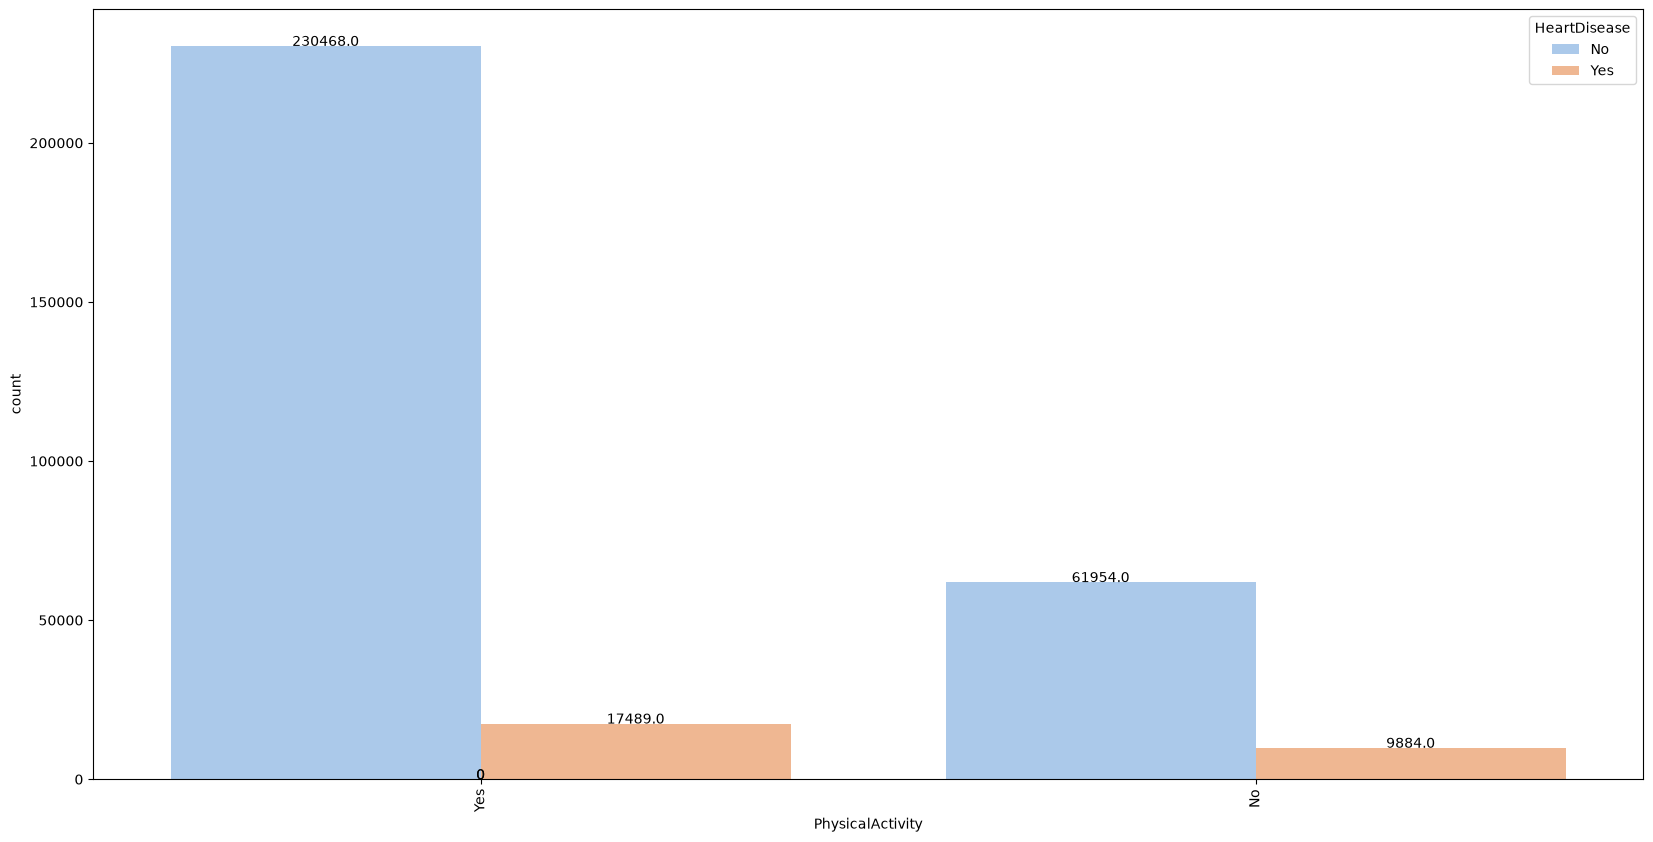

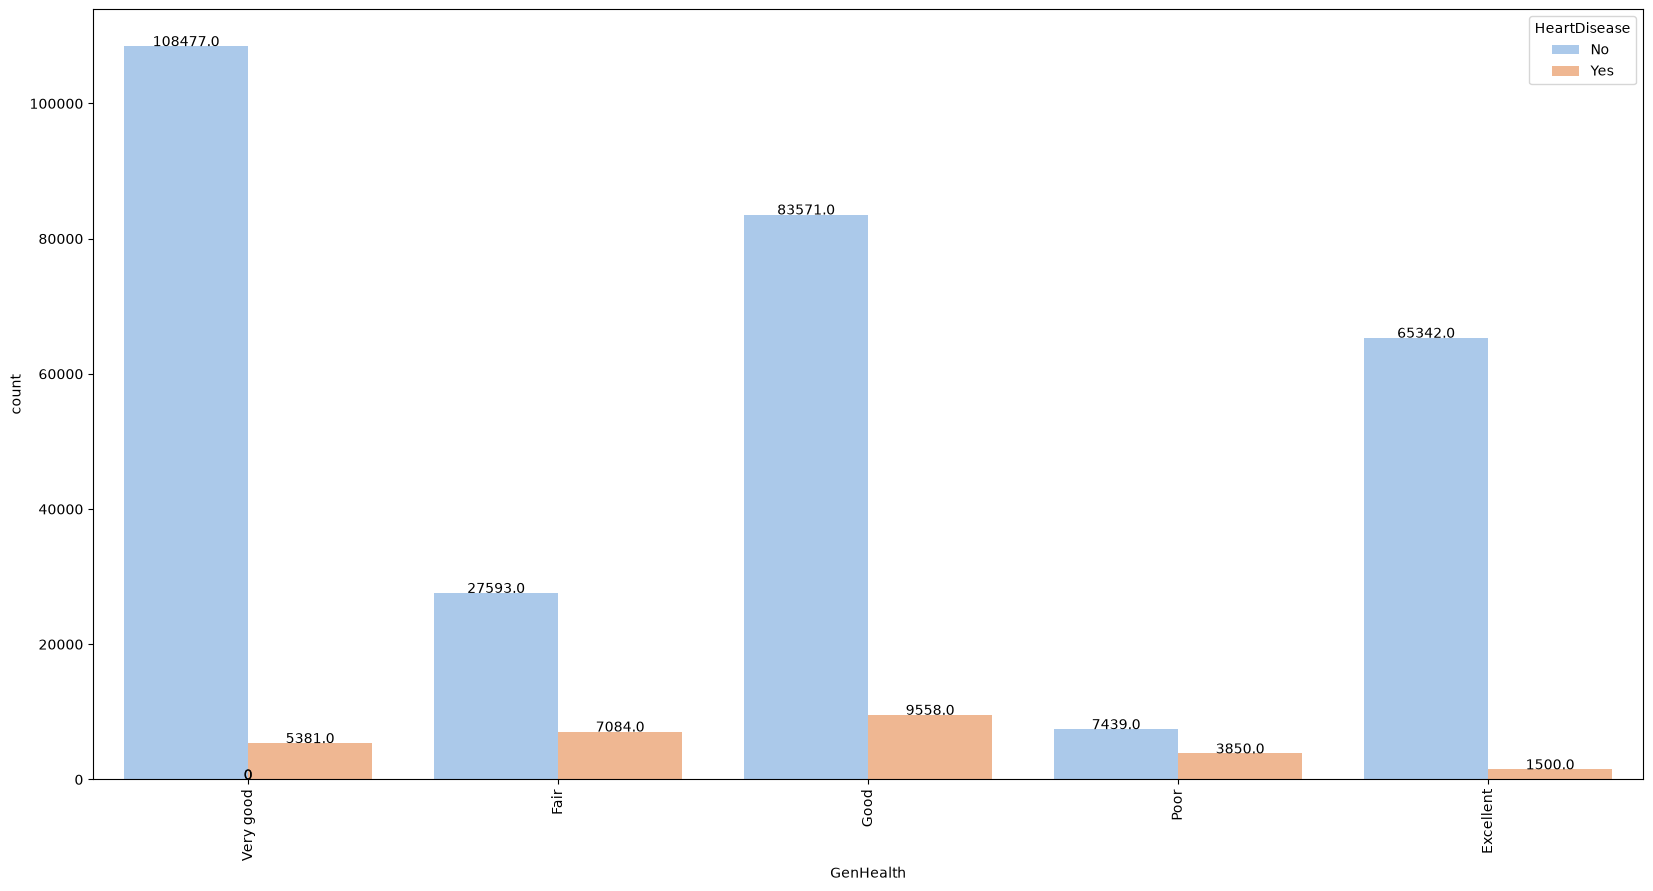

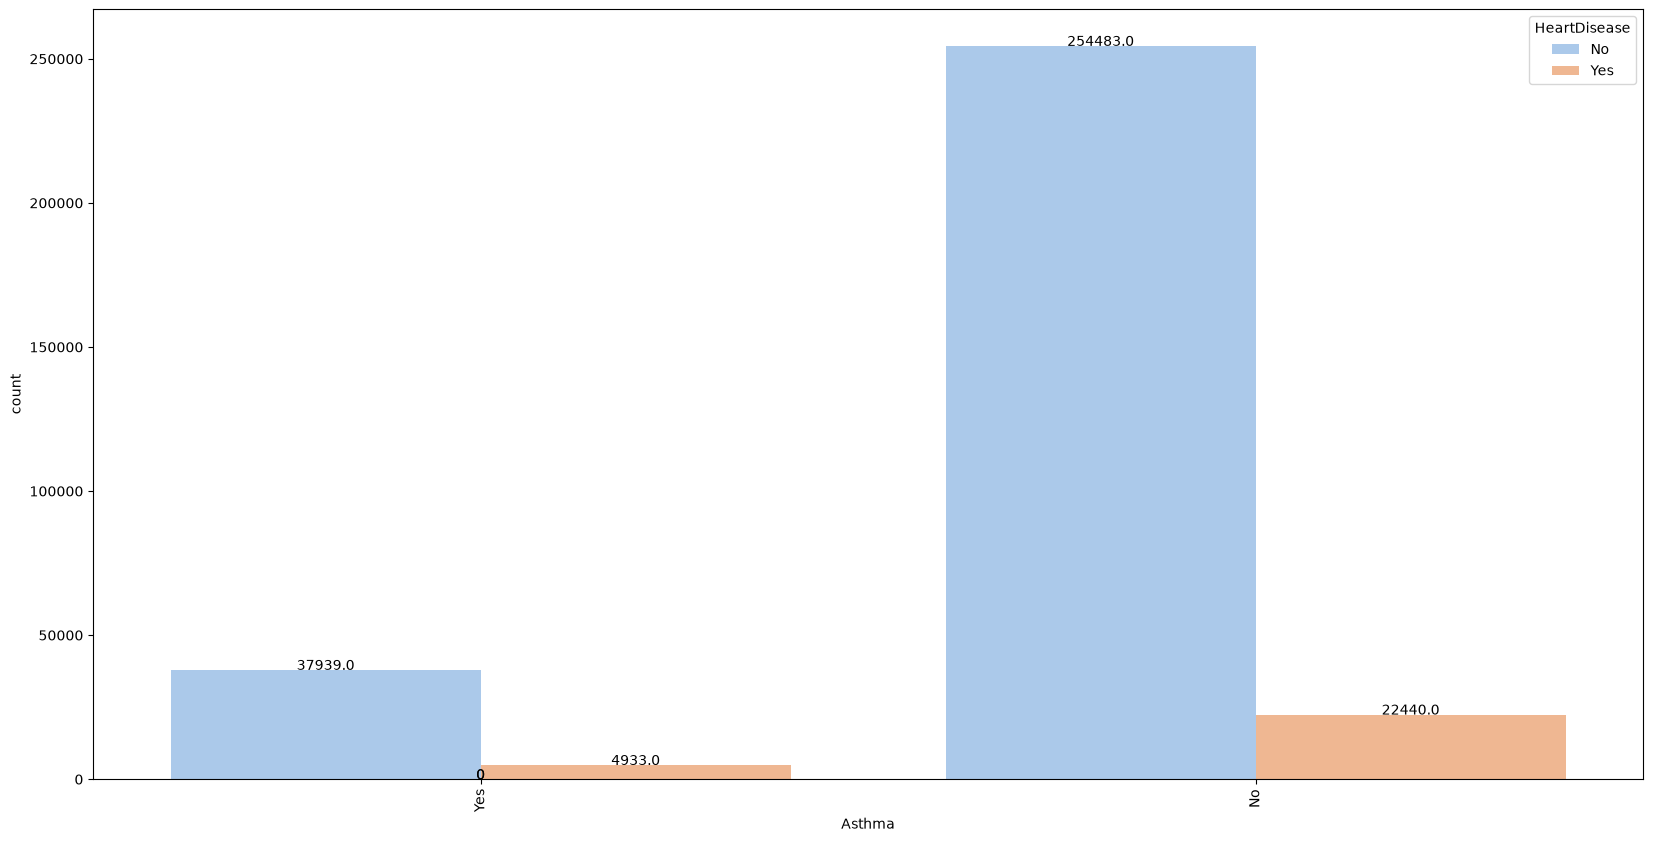

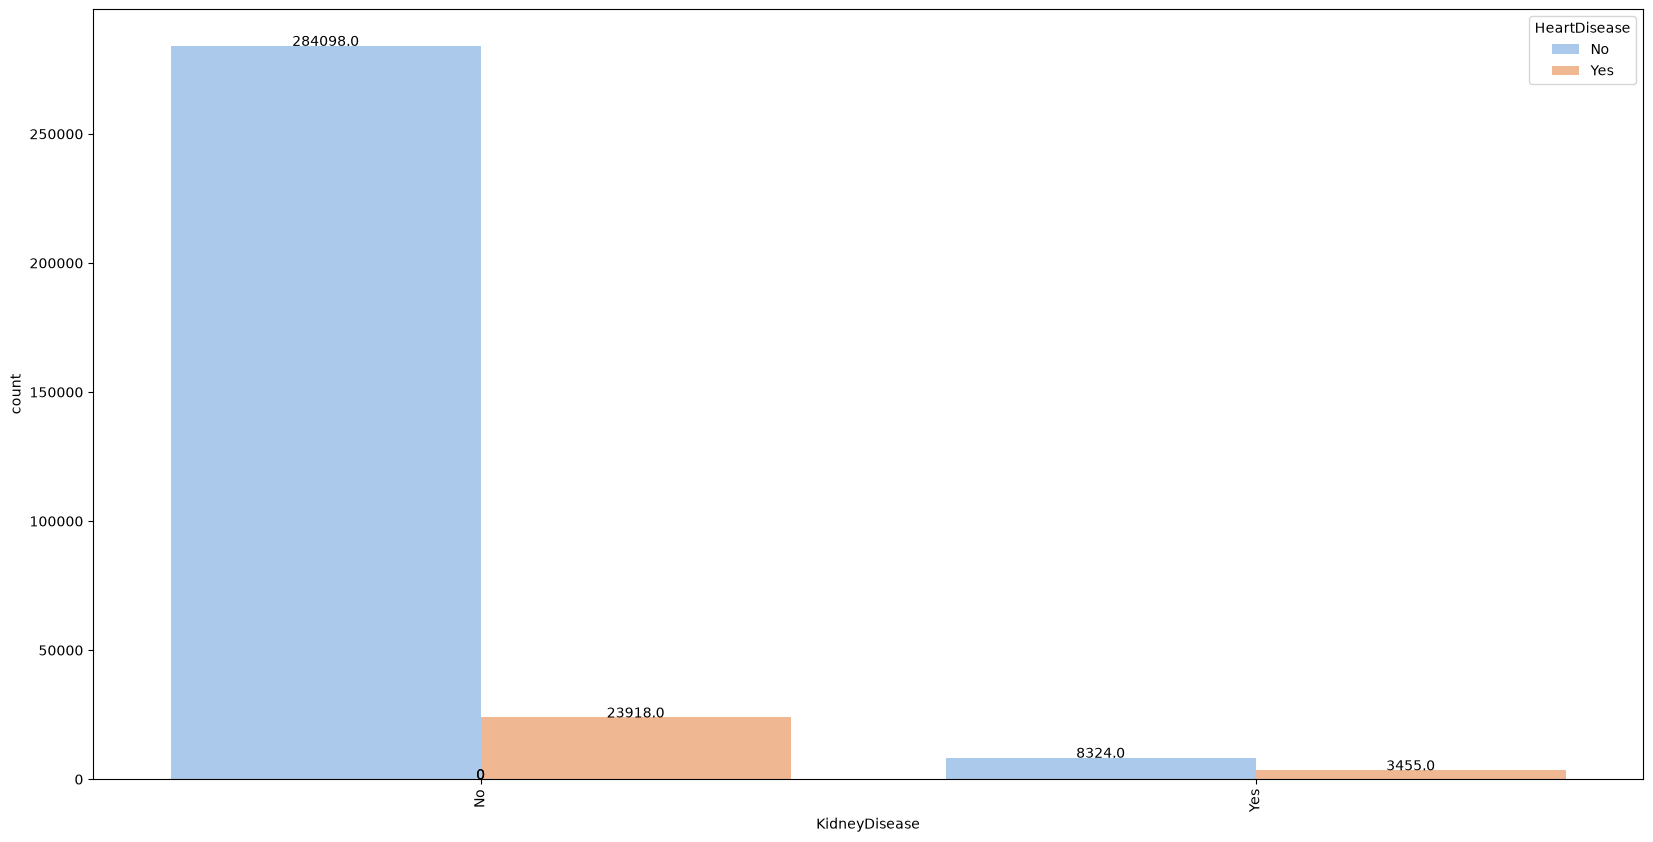

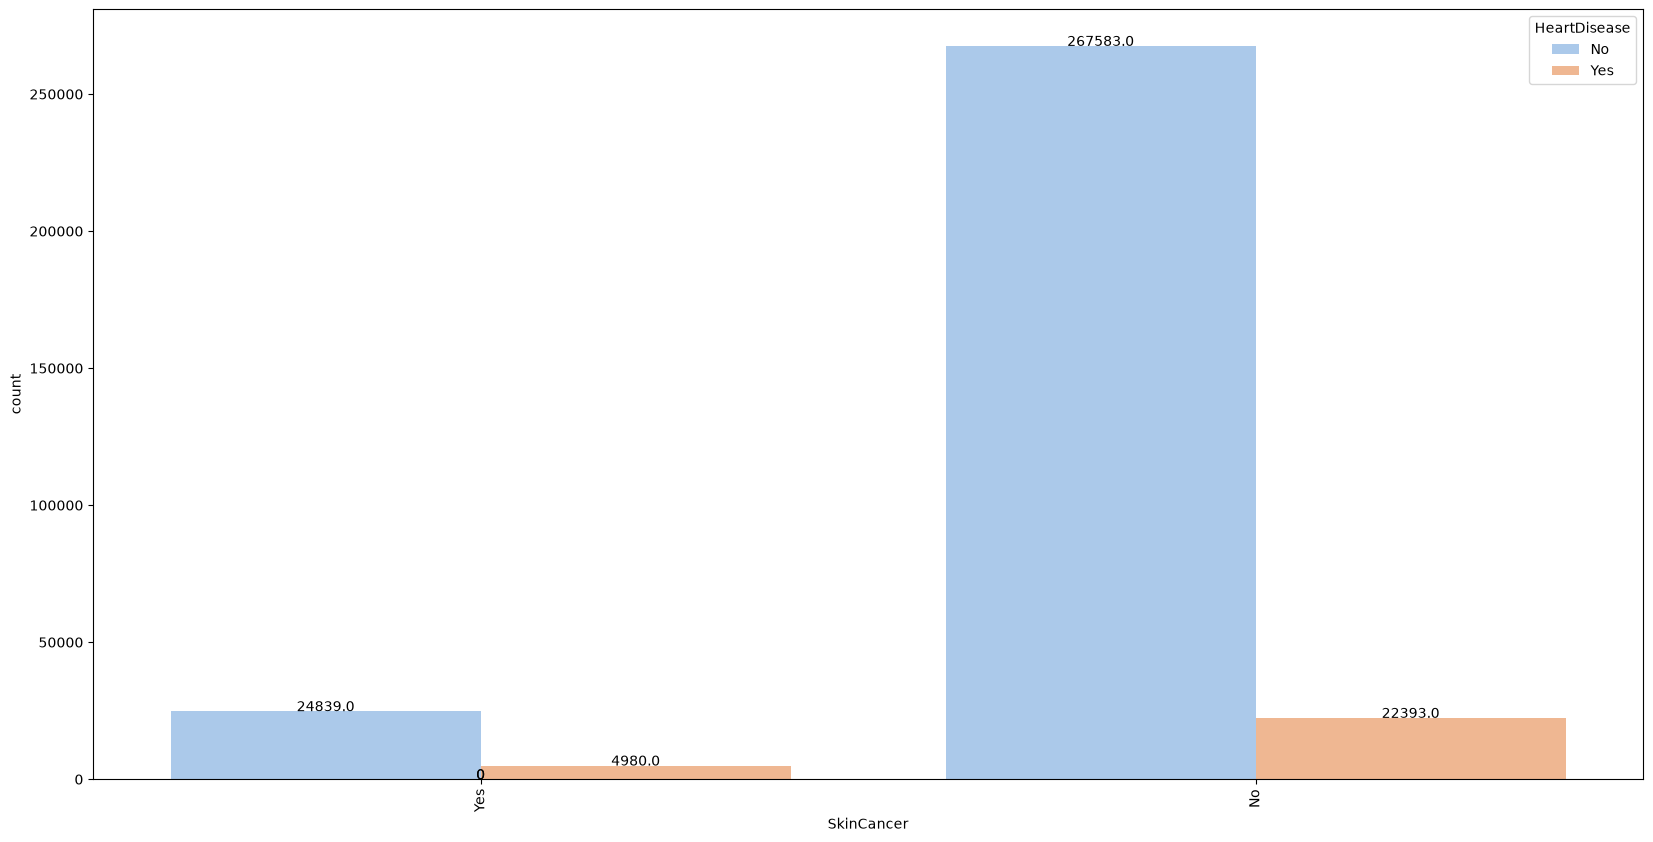

In [86]:
for feature in categorical_features:
  fig, ax1 = plt.subplots(figsize=(20,10))
  graph = sns.countplot(ax=ax1,x = feature , data = dataset, hue='HeartDisease', palette='pastel')
  graph.set_xticklabels(graph.get_xticklabels(),rotation=90)
  for p in graph.patches:
    height = p.get_height()
    graph.text(p.get_x()+p.get_width()/2., height + 0.1,height ,ha="center")

Let's look at outliers in numerical variables depending on several factors

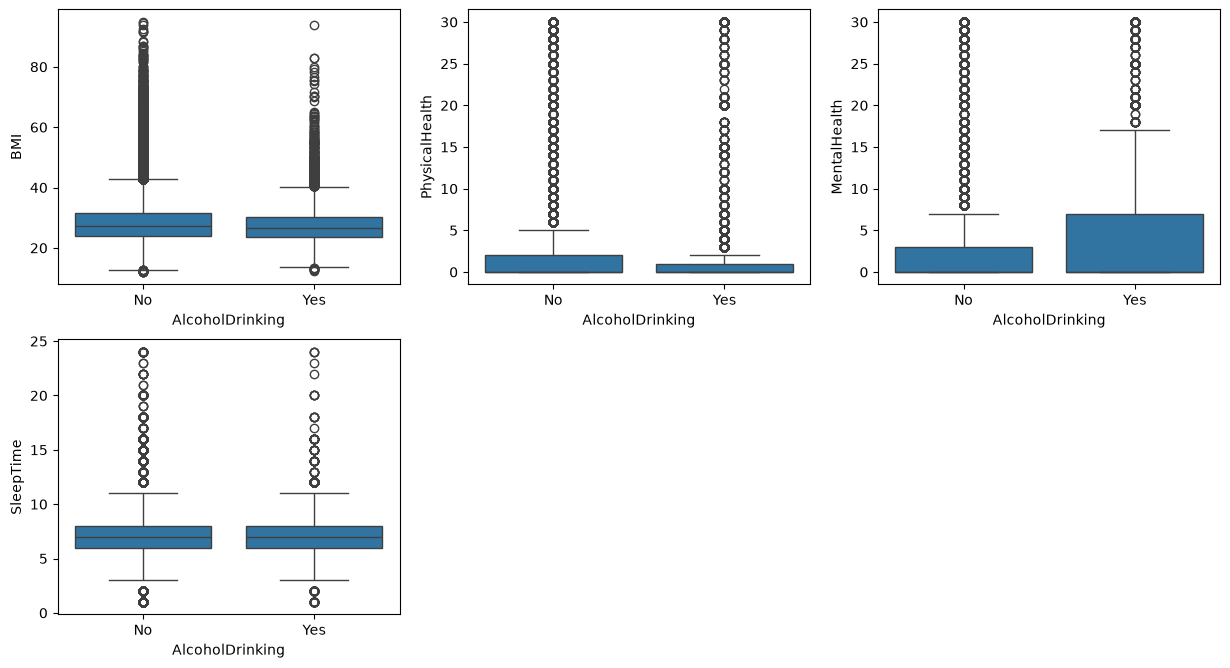

In [88]:
i=1
plt.figure(figsize=(15,25))
for feature in numeric_features:
    plt.subplot(6,3,i)
    sns.boxplot(y=dataset[feature], x = dataset['AlcoholDrinking'])
    i+=1

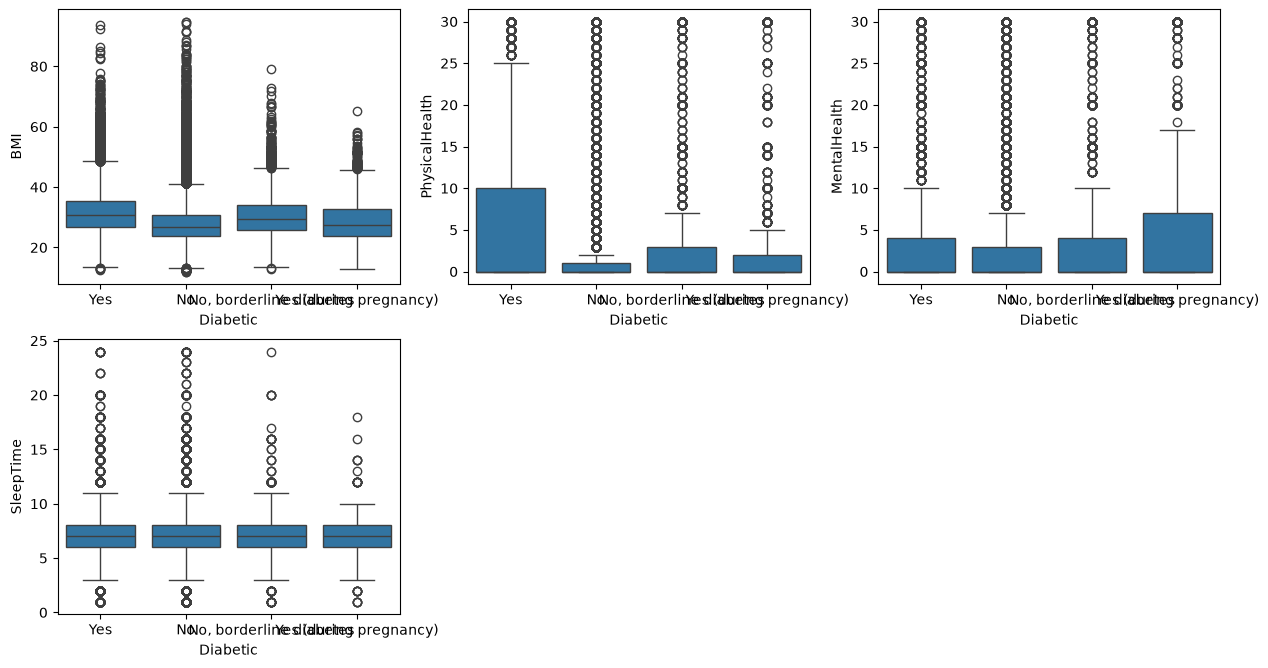

In [70]:
i=1
plt.figure(figsize=(15,25))
for feature in numeric_features:
    plt.subplot(6,3,i)
    sns.boxplot(y=dataset[feature], x = dataset['Diabetic'])
    i+=1

From all the graphs presented, it can be concluded that alcohol consumption and smoking are not the main factors in heart disease, atleast for the dataset we're working with.

Let's build a correlation table

In [90]:
correlation = dataset.corr()
print(correlation['HeartDisease'].sort_values(ascending = False),'\n')

HeartDisease        1.000000
AgeCategory         0.233432
DiffWalking         0.201258
Stroke              0.196835
PhysicalHealth      0.170721
Diabetic            0.168553
KidneyDisease       0.145197
Smoking             0.107764
SkinCancer          0.093317
Sex                 0.070040
BMI                 0.051803
Asthma              0.041444
Race                0.034854
MentalHealth        0.028591
SleepTime           0.008327
GenHealth          -0.011062
AlcoholDrinking    -0.032080
PhysicalActivity   -0.100030
Name: HeartDisease, dtype: float64 



Now, Lets Pick a Few Models, Train them and Evaulate them!

In [38]:
# Imports

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier


In [39]:
categorical_features = [
    'Smoking', 'AlcoholDrinking', 'Stroke', 'DiffWalking',
    'Sex', 'AgeCategory', 'Race', 'Diabetic', 'PhysicalActivity',
    'GenHealth', 'Asthma', 'KidneyDisease', 'SkinCancer'
]

In [40]:
y = dataset['HeartDisease']
dataset.drop('HeartDisease',axis=1,inplace=True)

In [43]:
y

0          No
1          No
2          No
3          No
4          No
         ... 
319790    Yes
319791     No
319792     No
319793     No
319794     No
Name: HeartDisease, Length: 319795, dtype: str

In [44]:
y = y.map({
    'No': 0,
    'Yes': 1
})

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    dataset,
    y,
    test_size=0.1,
    random_state=42,
    stratify=y
)

In [47]:
categorical_features = [
    'Smoking', 'AlcoholDrinking', 'Stroke', 'DiffWalking',
    'Sex', 'AgeCategory', 'Race', 'Diabetic', 'PhysicalActivity',
    'GenHealth', 'Asthma', 'KidneyDisease', 'SkinCancer'
]

In [48]:
from sklearn.preprocessing import OrdinalEncoder

enc = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train[categorical_features] = enc.fit_transform(
    X_train[categorical_features]
)

X_test[categorical_features] = enc.transform(
    X_test[categorical_features]
)

Using SMOTENC to balance the dataset

In [49]:
from imblearn.over_sampling import SMOTENC

categorical_indices = [
    X_train.columns.get_loc(column)
    for column in categorical_features
]

smote_nc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42
)

X_train_balanced, y_train_balanced = smote_nc.fit_resample(
    X_train,
    y_train
)

In [50]:
print("Before SMOTENC:")
print(y_train.value_counts())

print("\nAfter SMOTENC:")
print(y_train_balanced.value_counts())

Before SMOTENC:
HeartDisease
0    263179
1     24636
Name: count, dtype: int64

After SMOTENC:
HeartDisease
0    263179
1    263179
Name: count, dtype: int64


Let's build simple models and evaluate the quality of their training

In [52]:
models = [KNeighborsClassifier(), 
          LogisticRegression(),
          XGBClassifier(),
          ExtraTreesClassifier(),
          RandomForestClassifier(),
          LGBMClassifier()]


for m in models:
    m.fit(X_train_balanced, y_train_balanced)
    y_pred = m.predict(X_test)

    print(f'Model: {str(m)}')
    print(f'Accuracy_score: {accuracy_score(y_test,y_pred)}')
    print(f'Precission_score: {precision_score(y_test,y_pred, pos_label = 1)}')
    print(f'Recall_score: {recall_score(y_test,y_pred, pos_label= 1)}')
    print(f'F1-score: {f1_score(y_test,y_pred, pos_label= 1)}')
    print(f'Confusion Matrix : {confusion_matrix(y_test, y_pred)}')
    print('-'*30, '\n')

Model: KNeighborsClassifier()
Accuracy_score: 0.7636647904940588
Precission_score: 0.19629582965856118
Recall_score: 0.5692363902082572
F1-score: 0.2919243020423459
Confusion Matrix : [[22864  6379]
 [ 1179  1558]]
------------------------------ 



c:\CVD Project\cvd\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Model: LogisticRegression()
Accuracy_score: 0.7298311444652908
Precission_score: 0.2055860349127182
Recall_score: 0.753014249177932
F1-score: 0.3229901269393512
Confusion Matrix : [[21279  7964]
 [  676  2061]]
------------------------------ 

Model: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=

# Let's Summarize the results

- KNN: Achieved 76.37% accuracy, 19.63% precision, 56.92% recall, and 29.19% F1-score.
- Logistic Regression (LR): Achieved 72.98% accuracy, 20.56% precision, 75.30% recall, and 32.30% F1-score, giving it the highest recall among the six models.
- XGBoost: Achieved 88.01% accuracy, 31.52% precision, 34.16% recall, and 32.79% F1-score.
- Extra Trees: Achieved 85.82% accuracy, 24.77% precision, 32.26% recall, and 28.02% F1-score.
- Random Forest: Achieved 87.60% accuracy, 28.64% precision, 30.07% recall, and 29.34% F1-score.
- LightGBM: Achieved 87.59% accuracy, 31.37% precision, 37.92% recall, and 34.34% F1-score, the highest F1-score among the six models.

Model Selection — Logistic Regression: We will proceed with Logistic Regression because it achieved the highest recall of 75.30%. We are prioritising recall because, in a cardiovascular disease detection project, missing a positive case (a false negative) is particularly concerning. Higher recall means the model identifies a greater proportion of individuals whose records indicate heart disease, although this comes with a trade-off of more false positives.

We will use RandomizedSearchCV to identify the most suitable hyperparameters for Logistic Regression. It will evaluate randomly selected combinations of parameter values using cross-validation, with recall as the primary scoring metric, to find a configuration that improves the model's ability to identify positive heart disease cases. We will also monitor precision, F1-score, and accuracy to understand the trade-offs and select a model configuration that aligns with our project's objective.

In [53]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    recall_score,
    precision_score,
    f1_score,
    classification_report
)
from scipy.stats import loguniform

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

param_distributions = {
    "C": loguniform(0.001, 100),
    "solver": ["lbfgs"],
    "class_weight": [None, "balanced"]
}

random_search_lr = RandomizedSearchCV(
    estimator=logistic_model,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="recall",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search_lr.fit(X_train_balanced, y_train_balanced)

print("Best parameters:", random_search_lr.best_params_)
print("Best CV recall:", random_search_lr.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best parameters: {'C': np.float64(0.0010090061869151559), 'class_weight': 'balanced', 'solver': 'lbfgs'}
Best CV recall: 0.8015039018670894


RandomizedSearchCV evaluated 15 hyperparameter combinations across 3-fold cross-validation and identified the best Logistic Regression parameters as C = 0.001009, class_weight = 'balanced', and solver = 'lbfgs'.

In [55]:
best_lr = random_search_lr.best_estimator_

y_pred_lr = best_lr.predict(X_test)

print("Test Recall:", recall_score(y_test, y_pred_lr))
print("Test Precision:", precision_score(y_test, y_pred_lr))
print("Test F1:", f1_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Test Recall: 0.7500913408841797
Test Precision: 0.2044006371963361
Test F1: 0.32125811751819106
              precision    recall  f1-score   support

           0       0.97      0.73      0.83     29243
           1       0.20      0.75      0.32      2737

    accuracy                           0.73     31980
   macro avg       0.59      0.74      0.58     31980
weighted avg       0.90      0.73      0.79     31980



Despite hyperparameter tuning, Logistic Regression achieved a test recall of 75.01%, meaning it still failed to identify approximately 25% of positive cases. Therefore, we will experiment with decision-threshold tuning to improve recall by adjusting the probability threshold used to classify positive cases, while monitoring the impact on precision and F1-score.

In [56]:
from sklearn.linear_model import LogisticRegression

threshold_lr = LogisticRegression(
    C=0.0010090061869151559,
    class_weight="balanced",
    solver="lbfgs",
    max_iter=2000,
    random_state=42
)

threshold_lr.fit(X_train_balanced, y_train_balanced)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [57]:

# Get the probability of heart disease = 1
lr_val_probabilities = threshold_lr.predict_proba(
    X_test
)[:, 1]



print("Logistic Regression probabilities:")
print(lr_val_probabilities[:10])




Logistic Regression probabilities:
[0.41711293 0.32705533 0.30591017 0.58857064 0.19535411 0.2223709
 0.3066451  0.18643323 0.25660986 0.29589244]


In [58]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score, 
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

def evaluate_thresholds(y_true, probabilities, model_name):
    results = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Accuracy" : accuracy_score(y_true, predictions), 
            "Recall": recall_score(
                y_true, predictions, zero_division=0
            ),
            "Precision": precision_score(
                y_true, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_true, predictions, zero_division=0
            )
        })

    return pd.DataFrame(results)

lr_results = evaluate_thresholds(
    y_test, lr_val_probabilities, "Logistic Regression"
)



threshold_results = pd.concat(
    [lr_results],
    ignore_index=True
)

print(threshold_results.round(3).to_string(index=False))


              Model  Threshold  Accuracy  Recall  Precision    F1
Logistic Regression        0.1     0.335   0.978      0.112 0.201
Logistic Regression        0.2     0.464   0.940      0.132 0.231
Logistic Regression        0.3     0.565   0.898      0.153 0.261
Logistic Regression        0.4     0.651   0.837      0.176 0.291
Logistic Regression        0.5     0.729   0.750      0.204 0.321
Logistic Regression        0.6     0.798   0.642      0.243 0.353
Logistic Regression        0.7     0.854   0.512      0.295 0.374
Logistic Regression        0.8     0.894   0.323      0.363 0.342
Logistic Regression        0.9     0.914   0.121      0.488 0.194


After comparing the results across different decision thresholds, we have selected 0.4 for Logistic Regression. At this threshold, the model achieves 83.7% recall, 17.6% precision, 29.1% F1-score, and 65.1% accuracy. Although recall is lower than at a threshold of 0.3, the selected threshold offers a reasonable balance between identifying positive heart disease cases and maintaining overall accuracy, while keeping recall as our primary evaluation metric.

Lets Create a Gradio Interface for the model

In [59]:
import gradio as gr
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder


original_train = pd.read_csv('Data/2020/heart_2020_cleaned.csv')

categorical_input_features = ['Smoking', 'AlcoholDrinking', 'Stroke', 'DiffWalking', 'Sex', 'AgeCategory',
                              'Race', 'Diabetic', 'PhysicalActivity', 'GenHealth','Asthma', 'KidneyDisease', 'SkinCancer']
numeric_input_features = ['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']

input_encoder = OrdinalEncoder()
input_encoder.fit(original_train[categorical_input_features])


model_to_use = threshold_lr

def predict_heart_disease(
    BMI, Smoking, AlcoholDrinking, Stroke, PhysicalHealth, MentalHealth, DiffWalking,
    Sex, AgeCategory, Race, Diabetic, PhysicalActivity, GenHealth, SleepTime, Asthma,
    KidneyDisease, SkinCancer
):
    # Create a DataFrame for the single input
    input_data = pd.DataFrame({
        'BMI': [BMI],
        'Smoking': [Smoking],
        'AlcoholDrinking': [AlcoholDrinking],
        'Stroke': [Stroke],
        'PhysicalHealth': [PhysicalHealth],
        'MentalHealth': [MentalHealth],
        'DiffWalking': [DiffWalking],
        'Sex': [Sex],
        'AgeCategory': [AgeCategory],
        'Race': [Race],
        'Diabetic': [Diabetic],
        'PhysicalActivity': [PhysicalActivity],
        'GenHealth': [GenHealth],
        'SleepTime': [SleepTime],
        'Asthma': [Asthma],
        'KidneyDisease': [KidneyDisease],
        'SkinCancer': [SkinCancer]
    })

    # Preprocess categorical features using the fitted encoder
    input_data[categorical_input_features] = input_encoder.transform(input_data[categorical_input_features])

    # Convert all inputs to appropriate types for the model
    for col in numeric_input_features: # Ensure numeric features are float
        input_data[col] = pd.to_numeric(input_data[col])

    # The features in X_train are exactly in the order of original_train columns after dropping 'HeartDisease'
    # So we just need to make sure the input_data matches that order.
    input_data = input_data[X_train.columns] # Reorder to match X_train columns

    
   # Make prediction
    prediction_proba = model_to_use.predict_proba(input_data)

    print(f"Probabilities: {prediction_proba}")

    threshold = 0.4
    positive_probability = prediction_proba[0][1]

    if positive_probability >= threshold:
        result = (
            "Heart Disease: Yes\n"
            f"Probability of heart disease: {positive_probability:.2%}"
        )
    else:
        result = (
            "Heart Disease: No\n"
            f"Probability of no heart disease: {prediction_proba[0][0]:.2%}"
        )

    return result





c:\CVD Project\cvd\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [61]:
# Create Gradio interface
interface = gr.Interface(
    fn=predict_heart_disease,
    inputs=[
        gr.Number(label='BMI', value=27.3),
        gr.Dropdown(choices=original_train['Smoking'].unique().tolist(), label='Smoking', value='No'),
        gr.Dropdown(choices=original_train['AlcoholDrinking'].unique().tolist(), label='Alcohol Drinking', value='No'),
        gr.Dropdown(choices=original_train['Stroke'].unique().tolist(), label='Stroke', value='No'),
        gr.Number(label='PhysicalHealth (days of poor physical health)', value=0),
        gr.Number(label='MentalHealth (days of poor mental health)', value=0),
        gr.Dropdown(choices=original_train['DiffWalking'].unique().tolist(), label='Difficulty Walking', value='No'),
        gr.Dropdown(choices=original_train['Sex'].unique().tolist(), label='Sex', value='Female'),
        gr.Dropdown(choices=original_train['AgeCategory'].unique().tolist(), label='Age Category', value='55-59'),
        gr.Dropdown(choices=original_train['Race'].unique().tolist(), label='Race', value='White'),
        gr.Dropdown(choices=original_train['Diabetic'].unique().tolist(), label='Diabetic', value='No'),
        gr.Dropdown(choices=original_train['PhysicalActivity'].unique().tolist(), label='Physical Activity', value='Yes'),
        gr.Dropdown(choices=original_train['GenHealth'].unique().tolist(), label='General Health', value='Very good'),
        gr.Number(label='SleepTime (hours)', value=7),
        gr.Dropdown(choices=original_train['Asthma'].unique().tolist(), label='Asthma', value='No'),
        gr.Dropdown(choices=original_train['KidneyDisease'].unique().tolist(), label='Kidney Disease', value='No'),
        gr.Dropdown(choices=original_train['SkinCancer'].unique().tolist(), label='Skin Cancer', value='No')
    ],
    outputs='text',
    title='Heart Disease Prediction',
    description='Enter patient information to predict the likelihood of heart disease.'
)

In [62]:
interface.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Probabilities: [[0.82995343 0.17004657]]
